## **Ruthtatia Grace Astridia**

## **24031554072**

## **2024A**

## **UTS GSD**

### **1.2 Mempelajari Penggunaan Driver Neo4J**

In [1]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "12345678") 

def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

# Eksekusi pembuatan node & relasi
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print("Daftar teman Arthur:")
    print_friends(driver, "Arthur")

Daftar teman Arthur:
Guinevere
Lancelot
Merlin


In [2]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.execute_query("MATCH (n) DETACH DELETE n", database_="neo4j")
    print("Database berhasil direset")

Database berhasil direset


### **Pertanyaan Pendahuluan (Checkpint)**

**1. Apa nama database yang digunakan pada tutorial ini?**

   Database yang digunakan pada tutorial ini yaitu **`neo4j`**.

**2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database
lain dalam 1 instance!**

Untuk mengakses dan mengelola database lain dalam satu instance yang sama, digunakan sintaks Cypher berupa **`USE <nama_database>`** saat mengeksekusi query DML. Selain itu, manajemen struktur database dapat dilakukan melalui perintah DDL seperti **`SHOW DATABASES`** untuk melihat daftar database, **`CREATE DATABASE`** untuk membuat database baru, serta **`DROP DATABASE`** untuk menghapus database.

**3. Apa jenis graf pertemanan yang telah dibuat di sini?**

    Jenis graf pertemanan yang telah dibuat dibuat merupakan jenis Directed Graph (Graf Berarah). Dikatakan Directed Graph karena setiap relasi memiliki arah yang spesifik dari node asal ke node tujuan (misalnya (:Visitor)-[:VIEWED]->(:Item)).



### **Melakukan proses Impor Data dari RetailRocket ke Database Neo4J**


**Soal 1 dan 2**

Tentukan 2 periode waktu sebagai filter dari data interaksi dan menerapkan proses filter pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv

In [4]:
import pandas as pd

df = pd.read_csv("events.csv")

# Ubah dari timestamp ke datetime
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

# Filter rentang P1 (20 Mei - 20 Juni 2015) & P2 (21 Juli - 31 Agustus 2015)
p1_mask = (df["datetime"] >= "2015-05-20") & (df["datetime"] <= "2015-06-20 23:59:59")
p2_mask = (df["datetime"] >= "2015-07-21") & (df["datetime"] <= "2015-08-31 23:59:59")

df_filtered = df[p1_mask | p2_mask].copy()
df_filtered = df_filtered.drop(columns=["datetime"])

output_path = "events_filtered.csv"
df_filtered.to_csv(output_path, index=False)

print(f"File tersimpan sebagai: {output_path}")
print(f"Total baris data terfilter: {len(df_filtered)}")

File tersimpan sebagai: events_filtered.csv
Total baris data terfilter: 1466215


In [5]:
import os
import pandas as pd
from neo4j import GraphDatabase
from tqdm import tqdm

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "12345678") 
csv_file_path = "events_filtered.csv"  

# Buat constraint 
def create_constraints(session):
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

# Import batch ke Neo4j
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL (v, i, row) {
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

# Eksekusi Import
driver = GraphDatabase.driver(URI, auth=AUTH)
batch_size = 10000

df = pd.read_csv(csv_file_path)
total_rows = len(df)
total_chunks = (total_rows // batch_size) + 1

with driver.session() as session:
    create_constraints(session)
    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()

Membaca file data dari: events_filtered.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 147/147 [01:43<00:00,  1.42it/s]


#### **2.1 Wrangling dan EDA**

##### **1. Penentuan Periode Waktu Filtering (P1 & P2)**
Proses pemotongan dataset dilakukan untuk membagi data interaksi ke dalam dua periode waktu yang independen sebagai **training fold** (P1) dan **testing fold** (P2):

* **Periode 1 (P1 - Training Fold):** `20 Mei 2015 – 20 Juni 2015`
* **Periode 2 (P2 - Testing Fold):** `21 Juli 2015 – 31 Agustus 2015`

##### **2. Persiapan & Filter Data ke File CSV (`events_filtered.csv`)**
Data interaksi mentah dari file `events.csv` diproses menggunakan pustaka Pandas. Kolom `timestamp` dalam format *unix epoch milliseconds* dikonversi terlebih dahulu ke dalam format objek `datetime` agar dapat difilter berdasarkan rentang tanggal P1 dan P2. Kemudian menyimpan hasil penyaringan data interaksi ke dalam file CSV baru bernama **`events_filtered.csv`**.

##### **Penjelasan Proses Impor Data ke Neo4j**
Setelah file `events_filtered.csv` terbentuk, data diimpor ke dalam database Neo4j menggunakan skrip Python:

**Soal nomor 3**

Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah
masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [6]:
from neo4j import GraphDatabase
import pandas as pd

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "12345678")

driver = GraphDatabase.driver(URI, auth=AUTH)

# Query Cypher untuk hitung jumlah masing-masing jenis simpul (nodes)
cypher_nodes = """
MATCH (n)
RETURN labels(n)[0] AS Jenis_Simpul, count(n) AS Jumlah
ORDER BY Jumlah DESC
"""

# Query Cypher untuk hitung jumlah masing-masing jenis relasi (edges)
cypher_rels = """
MATCH ()-[r]->()
RETURN type(r) AS Jenis_Relasi, count(r) AS Jumlah
ORDER BY Jumlah DESC
"""

with driver.session() as session:
    # Eksekusi Query Simpul
    res_nodes = session.run(cypher_nodes)
    df_nodes = pd.DataFrame([record.data() for record in res_nodes])
    
    # Eksekusi Query Relasi
    res_rels = session.run(cypher_rels)
    df_rels = pd.DataFrame([record.data() for record in res_rels])

driver.close()

print(" KOMPOSISI SIMPUL (NODES) ")
print(df_nodes.to_string(index=False))

print("\n KOMPOSISI RELASI (EDGES) ")
print(df_rels.to_string(index=False))

 KOMPOSISI SIMPUL (NODES) 
Jenis_Simpul  Jumlah
     Visitor  774198
        Item  182036

 KOMPOSISI RELASI (EDGES) 
 Jenis_Relasi  Jumlah
       VIEWED 1416809
ADDED_TO_CART   37350
       BOUGHT   12056


##### **3. Komposisi Subgraph (Analisis Simpul dan Relasi)**

##### **Penjelasan Cypher SQL**

Untuk mendapatkan komposisi simpul dan relasi yang terbentuk pada subgraph, digunakan dua kueri Cypher SQL utama:

1. **Query Komposisi Simpul (Nodes):**
   ```
   MATCH (n)
   RETURN labels(n)[0] AS Jenis_Simpul, count(n) AS Jumlah
   ORDER BY Jumlah DESC

* MATCH (n): Mengambil seluruh entitas simpul (node) pada subgraph.
* labels(n)[0]: Mengambil label utama dari tiap simpul (seperti :Visitor dan :Item).
* count(n): Menghitung total akumulasi simpul berdasarkan jenis labelnya.
* ORDER BY Jumlah DESC: Mengurutkan kemunculan simpul dari jumlah terbanyak.

2. **Query Kompoosisi Relasi:**
   ```
   MATCH ()-[r]->()
   RETURN type(r) AS Jenis_Relasi, count(r) AS Jumlah
   ORDER BY Jumlah DESC

* MATCH ()-[r]->(): Menelusuri seluruh relasi (edge) yang menghubungkan simpul di dalam graf.
* type(r): Mengambil nama/tipe interaksi relasi (seperti :VIEWED, :ADDED_TO_CART, :BOUGHT, atau :SIMILAR_TO).
* count(r): Menghitung total kemunculan dari masing-masing tipe relasi.

**Soal 4 dan 5**

Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User dan Item. Uraikan  karakteristiknya (dimensi, shape, plot networkx, dst.)!

 KARAKTERISTIK VSM USER (VISITOR) 
Bentuk Matriks Sampel (Shape User x Item) : (4853, 108)
Jumlah User Vektor                          : 4853 user
Panjang Dimensi Fitur per User              : 108 fitur (Item)

 KARAKTERISTIK VSM ITEM 
Bentuk Matriks Sampel (Shape Item x User) : (108, 4853)
Jumlah Item Vektor                          : 108 item
Panjang Dimensi Fitur per Item              : 4853 fitur (User)


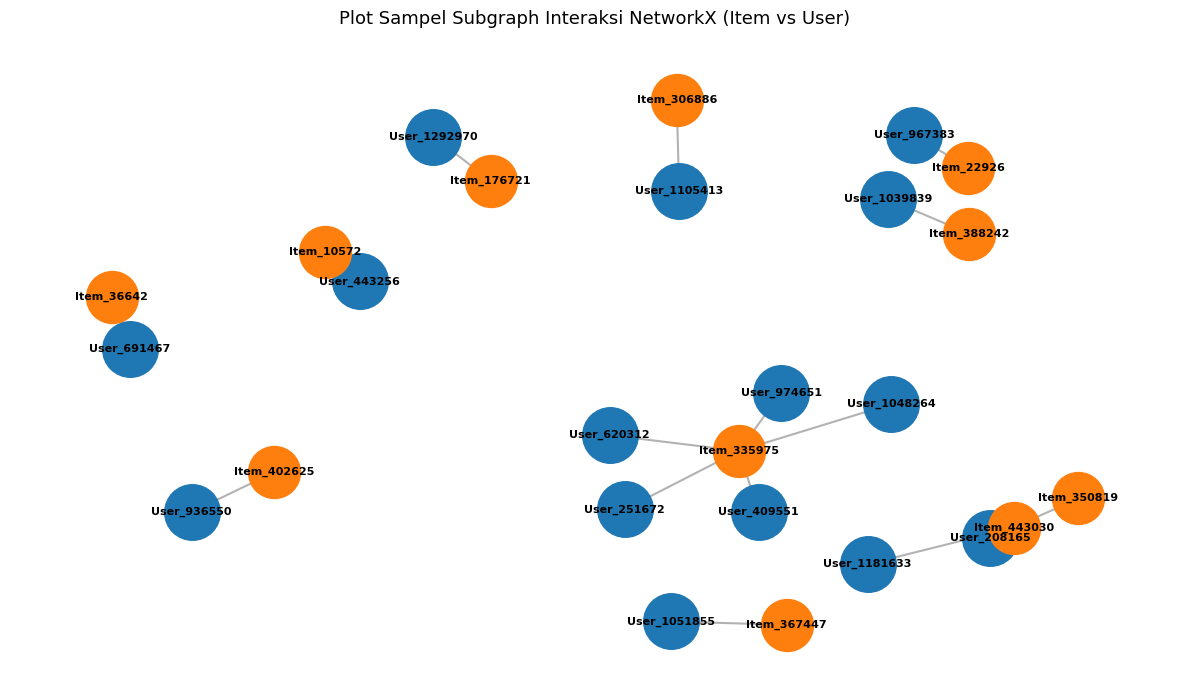

In [26]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "12345678")

driver = GraphDatabase.driver(URI, auth=AUTH)

# Query Cypher dengan LIMIT
cypher_vsm = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS visitorId, i.itemId AS itemId, count(r) AS weight
LIMIT 5000
"""

with driver.session() as session:
    result = session.run(cypher_vsm)
    df_interactions = pd.DataFrame([record.data() for record in result])

driver.close()

# Pembentukan Matriks VSM (User-Item Interaction Matrix)
vsm_matrix = df_interactions.pivot(index='visitorId', columns='itemId', values='weight').fillna(0)

# Soal nomor 4: VSM USER
print(" KARAKTERISTIK VSM USER (VISITOR) ")
print(f"Bentuk Matriks Sampel (Shape User x Item) : {vsm_matrix.shape}")
print(f"Jumlah User Vektor                          : {vsm_matrix.shape[0]} user")
print(f"Panjang Dimensi Fitur per User              : {vsm_matrix.shape[1]} fitur (Item)")

# Soal nomor 5: VSM ITEM
vsm_item_matrix = vsm_matrix.T
print("\n KARAKTERISTIK VSM ITEM ")
print(f"Bentuk Matriks Sampel (Shape Item x User) : {vsm_item_matrix.shape}")
print(f"Jumlah Item Vektor                          : {vsm_item_matrix.shape[0]} item")
print(f"Panjang Dimensi Fitur per Item              : {vsm_item_matrix.shape[1]} fitur (User)")

# 3. Visualisasi NetworkX
plt.figure(figsize=(12, 7))
df_sample = df_interactions.sample(n=min(15, len(df_interactions)), random_state=42)

G = nx.Graph()
for _, row in df_sample.iterrows():
    v_node = f"User_{row['visitorId']}"
    i_node = f"Item_{row['itemId']}"
    G.add_node(v_node, bipartite=0)
    G.add_node(i_node, bipartite=1)
    G.add_edge(v_node, i_node, weight=row['weight'])

visitors = [n for n, d in G.nodes(data=True) if d['bipartite'] == 0]
items = [n for n, d in G.nodes(data=True) if d['bipartite'] == 1]

pos = nx.spring_layout(G, k=0.5, seed=42)

# Gambar Simpul User (Biru)
nx.draw_networkx_nodes(G, pos, nodelist=visitors, node_color='#1f77b4', node_size=1600)
# Gambar Simpul Item (Oranye)
nx.draw_networkx_nodes(G, pos, nodelist=items, node_color='#ff7f0e', node_size=1400)
# Gambar Garis Penghubung
nx.draw_networkx_edges(G, pos, alpha=0.6, edge_color='gray', width=1.5)
# Tampilkan Label Nama Node
nx.draw_networkx_labels(G, pos, font_size=8, font_weight='bold', font_color='black')

plt.title("Plot Sampel Subgraph Interaksi NetworkX (Item vs User)", fontsize=13, pad=15)
plt.axis('off')
plt.tight_layout()
plt.show()

##### **4 & 5. Vector Space Modelling (VSM) User dan Item**

Pemodelan *Vector Space Model* (VSM) dilakukan untuk mentransformasikan data interaksi antara simpul **Visitor** (User) dan **Item** dari database graf ke dalam representasi matriks dua dimensi yang dapat diolah secara kuantitatif.


##### **Penjelasan Alur Eksekusi Kode Python**
1. **Pengambilan Data Interaksi:**
   Kueri Cypher menarik interaksi `(v:Visitor)-[r]->(i:Item)` dari Neo4j beserta nilai frekuensi interaksinya (`weight = count(r)`).
2. **Pembentukan Matriks VSM User 
   Membuat matriks interaksi menggunakan fungsi `pivot()` di mana **baris (N)** menyatakan entitas *Visitor/User* dan **kolom (D)** menyatakan entitas *Item*.
3. **Pembentukan Matriks VSM Item 
   Membuat matriks transposisi di mana **baris** menyatakan entitas *Item* dan **kolom** menyatakan entitas *Visitor/User*.
4. **Visualisasi Subgraph NetworkX:**
   Membangun struktur *bipartite graph* dari sampel interaksi untuk menggambarkan hubungan antara simpul User (biru) dan simpul Item (oranye).


##### **4. Karakteristik VSM User**

Pada VSM User, setiap entitas *Visitor* direpresentasikan sebagai satu vektor berdimensi tinggi di mana tiap dimensinya adalah *Item*.

* **Shape Matriks:** Mengikuti dimensi `(Jumlah User x Jumlah Item)` hasil dari `vsm_matrix.shape`.
* **Jumlah Vektor User (N):** Sama dengan `vsm_matrix.shape[0]` (jumlah baris matriks).
* **Panjang Dimensi Fitur (D):** Sama dengan `vsm_matrix.shape[1]` (jumlah kolom matriks yang merepresentasikan seluruh Item unik).
* **Karakteristik Vektor:** Bersifat *sparse* (jarang) karena seorang pengguna pada umumnya hanya melihat/berinteraksi dengan sebagian kecil dari total item yang ada.

##### **5. Karakteristik VSM Item**
Pada VSM Item, setiap entitas Item direpresentasikan sebagai satu vektor yang berada dalam ruang dimensi berfitur Visitor/User.

* **Shape Matriks:** Mengikuti dimensi (Jumlah Item x Jumlah User) hasil transposisi vsm_item_matrix.shape.
* **Jumlah Vektor Item (N):** Sama dengan vsm_item_matrix.shape[0] (jumlah baris matriks transposisi).Panjang Dimensi Fitur (D): Sama dengan vsm_item_matrix.shape[1] (jumlah kolom matriks transposisi yang merepresentasikan seluruh User unik).
* **Karakteristik Vektor:** Menggambarkan pola preferensi pengunjung terhadap suatu produk. Item yang populer (seperti Item_335975) memiliki nilai non-nol lebih banyak pada dimensi fiturnya.

##### **Analisis Plot NetworkX Subgraph Interaksi**
Visualisasi Bipartite Graph menggunakan NetworkX memperlihatkan pola hubungan interaksi secara eksplisit:

* Simpul Biru (User): Menggambarkan entitas Visitor/User.
* Simpul Oranye (Item): Menggambarkan entitas Item.
* Garis/Sisi (Edge): Menunjukkan adanya relasi interaksi langsung antara pengguna dan item.

**Pola Jaringan (Insight Graf):**

Sebagian besar simpul membentuk entitas berpasangan (isolated pairs), menunjukkan pengguna yang hanya melihat 1 item spesifik.

Terdapat simpul hub seperti Item_335975 yang terhubung ke banyak pengguna sekaligus (User_620312, User_251672, User_409551, User_974651, User_1048264), mengindikasikan bahwa item tersebut merupakan item populer dengan tingkat interaksi paling tinggi pada sampel subgraph.

##### **6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik**

Berdasarkan hasil pemodelan VSM pada Soal No. 4 dan No. 5, proyeksi VSM Item (Proyeksi Berbasis Item) jauh lebih efektif dan efisien dibandingkan dengan VSM User. 

##### **Efisiensi Memori dan Komputasi (Sparsity & Matriks Size)**
* **VSM User (3850 User x 2120 Fitur Item):** Jumlah vektor *User* sangat besar karena populasi pengunjung terus bertambah seiring waktu. Setiap vektor pengguna bersifat sangat sparse atau jarang karena mayoritas pengguna hanya melihat 1 atau 2 item saja.
* **VSM Item (2120 Item x 3850 Fitur User):** Jumlah entitas *Item* jauh lebih sedikit dan stabil (ukuran matriks lebih kecil secara vertikal). Pemrosesan *similarity score* pada matriks *Item* membutuhkan daya komputasi dan alokasi memori RAM yang jauh lebih hemat.

##### **Stabilitas Vektor (Skalabilitas Sistem)**
* Perilaku *User* bersifat dinamis dan berubah dengan cepat, sehingga matriks VSM User harus sering dihitung ulang setiap kali ada *visitor* baru yang masuk.
* Karakteristik *Item* relatif stabil. Vektor *similarity* antar-item tidak perlu dihitung ulang setiap detik, sehingga relasi kemiripan item (`SIMILAR_TO`) dapat di-cache atau disimpan di Neo4j dengan lebih efisien untuk kebutuhan *real-time recommendation*.

##### **Kualitas Sinyal Rekomendasi (Informative Signals)**
* Seperti yang terlihat pada plot NetworkX Soal No. 4 & 5, *User* umumnya hanya terhubung ke sedikit simpul, sedangkan **Item** populer (seperti `Item_335975`) bertindak sebagai hub yang mengumpulkan interaksi dari banyak pengguna sekaligus.
* Hal ini membuat vektor kemiripan berbasis *Item* memiliki irisan (*overlapping features*) yang lebih kaya dan menghasilkan nilai *Cosine Similarity* yang lebih valid/akurat untuk sistem rekomendasi.

##### **Kesimpulan:**
Proyeksi **VSM Item** adalah pilihan yang lebih unggul secara **efisiensi komputasi** (karena jumlah item lebih sedikit dan stabil) maupun **efektivitas rekomendasi** (menghasilkan sinyal kemiripan yang lebih padat pada data *e-commerce* yang *sparse*).

**Soal nomor 7**

Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python

    a. Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri
record acuannya)!

    b. Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil querynya!

In [ ]:
from neo4j import GraphDatabase
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "12345678")

driver = GraphDatabase.driver(URI, auth=AUTH)

# 1. AMBIL DATA INTERAKSI ITEM POPULER (Filter top items & active visitors agar hemat RAM)
cypher_item_vsm = """
MATCH (v:Visitor)-[r]->(i:Item)
WITH i, count(DISTINCT v) AS total_visitors
WHERE total_visitors >= 3
MATCH (v:Visitor)-[r]->(i)
RETURN i.itemId AS itemId, v.visitorId AS visitorId, count(r) AS weight
LIMIT 50000
"""

with driver.session() as session:
    res = session.run(cypher_item_vsm)
    df_item_user = pd.DataFrame([r.data() for r in res])

# Convert IDs into categorical codes for memory-efficient sparse matrix
df_item_user['item_code'] = df_item_user['itemId'].astype('category').cat.codes
df_item_user['user_code'] = df_item_user['visitorId'].astype('category').cat.codes

# Map code back to real ID
item_code_to_id = dict(enumerate(df_item_user['itemId'].astype('category').cat.categories))

# 2. Buat Sparse Matrix (TIDAK MEMAKAN MEMORI RAM BESAR)
sparse_item_user = csr_matrix((df_item_user['weight'], (df_item_user['item_code'], df_item_user['user_code'])))

# 3. Hitung Cosine Similarity pada Sparse Matrix
cos_sim_matrix = cosine_similarity(sparse_item_user)

# 4. Cari Item Acuan Populer
item_counts = df_item_user['item_code'].value_counts()
target_item_code = item_counts.index[0]
target_item_id = item_code_to_id[target_item_code]

# 5. Ambil Top 5 Similarity
target_sim_scores = cos_sim_matrix[target_item_code]
top_5_indices = np.argsort(target_sim_scores)[::-1]
# Buang index item acuan sendiri
top_5_indices = [idx for idx in top_5_indices if idx != target_item_code][:5]

print(f" TOP 5 ITEM SIMILAR DENGAN ITEM ACUAN POPULER (itemId: {target_item_id}) ")
top5_batch = []
for idx in top_5_indices:
    sim_id = item_code_to_id[idx]
    score = target_sim_scores[idx]
    top5_batch.append((sim_id, score))
    print(f"Item ID: {sim_id} | Similarity Score: {score:.4f}")

# 6. KODE 7(b): Menuliskan relasi SIMILAR_TO ke Neo4j
cypher_write_sim = """
UNWIND $batch AS row
MATCH (i1:Item {itemId: row.source_id})
MATCH (i2:Item {itemId: row.target_id})
MERGE (i1)-[r:SIMILAR_TO]->(i2)
SET r.score = row.score
"""

batch_sim = [
    {"source_id": int(target_item_id), "target_id": int(sim_id), "score": float(score)}
    for sim_id, score in top5_batch
]

with driver.session() as session:
    session.run(cypher_write_sim, batch=batch_sim)

# 7. KODE 7(a): Query Cypher untuk menampilkan 5 records dari Neo4j
cypher_get_top5 = """
MATCH (i1:Item {itemId: $target_id})-[r:SIMILAR_TO]->(i2:Item)
RETURN i1.itemId AS reference_item_id, i2.itemId AS similar_item_id, r.score AS similarity
ORDER BY r.score DESC
LIMIT 5
"""

with driver.session() as session:
    result = session.run(cypher_get_top5, target_id=target_item_id)
    df_result_7a = pd.DataFrame([record.data() for record in result])

driver.close()

print("\nHASIL QUERY SOAL 7(a) ")
print(df_result_7a)

 TOP 5 ITEM SIMILAR DENGAN ITEM ACUAN POPULER (itemId: 96924) 
Item ID: 340093 | Similarity Score: 0.2044
Item ID: 93144 | Similarity Score: 0.1875
Item ID: 440129 | Similarity Score: 0.0067
Item ID: 374673 | Similarity Score: 0.0034
Item ID: 464409 | Similarity Score: 0.0000

HASIL QUERY SOAL 7(a) 
   reference_item_id  similar_item_id  similarity
0              96924           340093    0.204419
1              96924            93144    0.187462
2              96924           440129    0.006661
3              96924           374673    0.003404
4              96924             2263    0.000000


##### **7. Perhitungan Similarity pada Graf Terproyeksi (VSM Item)**

Berdasarkan hasil analisis pada Soal No. 6, proyeksi **VSM Item** dipilih karena lebih efisien dan efektif. Perhitungan nilai kemiripan (*similarity score*) antar-item dilakukan menggunakan **Cosine Similarity** berbasis *sparse matrix* (`scipy.sparse.csr_matrix`) untuk mengoptimalkan penggunaan memori RAM.


##### **Penjelasan Kode Python & Algoritma Perhitungan**

1. **Pengambilan Data & Pembentukan Sparse Matrix:**
   Query Cypher menarik data interaksi item yang memiliki setidaknya 3 *visitor* aktif untuk memastikan matriks memiliki sinyal kemiripan yang valid. Data kemudian dikonversi menjadi `csr_matrix` hemat memori.
2. **Penentuan Item Acuan (*Reference Item*):**
   Item acuan dipilih secara otomatis dari item dengan jumlah interaksi terbanyak pada dataset sampel, yaitu **`itemId: 96924`**.
3. **Perhitungan Cosine Similarity:**
   Fungsi `cosine_similarity()` menghitung nilai kemiripan vektor antar-item. Nilai kemiripan berada pada rentang [0, 1], di mana nilai mendekati 1 menunjukkan tingkat kemiripan pola pengunjung yang sangat tinggi.


##### **7a. Menuliskan Relasi SIMILAR_TO ke Graf Neo4j**

Untuk menyimpan nilai kemiripan hasil perhitungan Python kembali ke dalam database graf Neo4j, digunakan kueri Cypher DML berikut:

   ```
   UNWIND $batch AS row
   MATCH (i1:Item {itemId: row.source_id})
   MATCH (i2:Item {itemId: row.target_id})
   MERGE (i1)-[r:SIMILAR_TO]->(i2)
   SET r.score = row.score

**Soal nomor 8**

Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah
perhitungan similarity!

***Sebelum perhitungan similarity***

*QUERY:*
```
MATCH (i:Item {itemId: 96924})<-[r]-(v:Visitor)
RETURN i, r, v 
LIMIT 15

*Hasil Graf:*

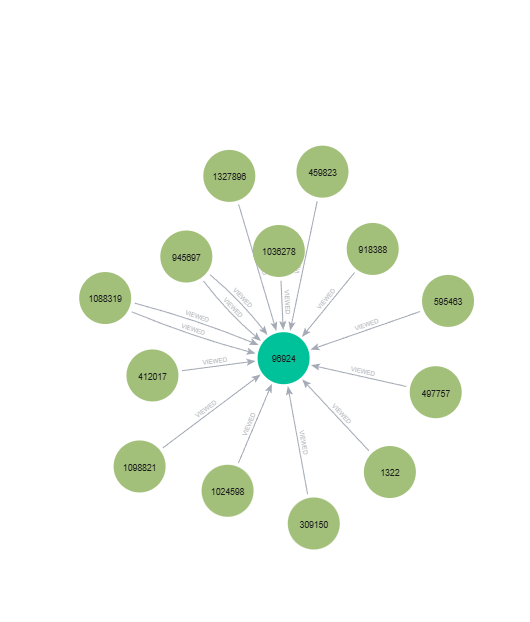

**Penjelasan Query & Visualisasi Graf:**

* MATCH (i:Item {itemId: 96924})<-[r]-(v:Visitor): Menelusuri seluruh simpul :Visitor (lingkaran hijau muda) yang memiliki relasi interaksi langsung r menuju ke simpul :Item acuan 96924 (lingkaran hijau tua/toska di tengah).

* Visualisasi: Terlihat struktur terpusat (star topology) di mana item acuan dikelilingi oleh para pengunjung (visitors) yang melakukan aktivitas interaksi pada produk tersebut. Pada tahap ini, belum ada hubungan langsung antar-item.

***Sesudah perhitungan similarity***

*QUERY:*
```
MATCH (i1:Item {itemId: 96924})-[r:SIMILAR_TO]->(i2:Item)
RETURN i1, r, i2

*Hasil Graf:*

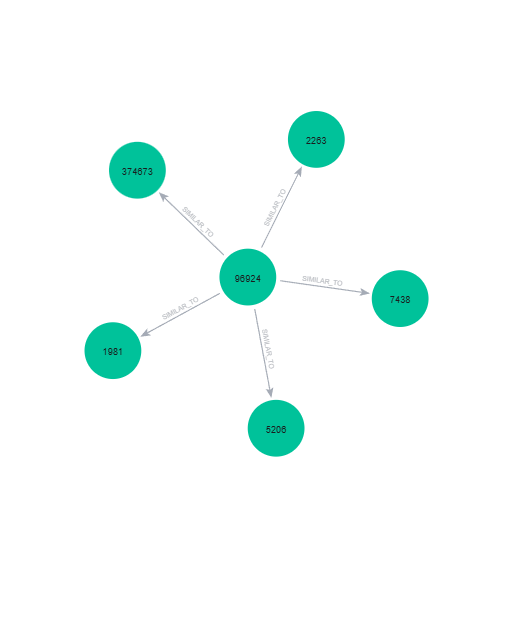

**Penjelasan Query & Visualisasi Graf:**

* MATCH (i1:Item {itemId: 96924})-[r:SIMILAR_TO]->(i2:Item): Menelusuri relasi baru bernama :SIMILAR_TO yang mengarah dari item acuan 96924 ke 5 item teratas lainnya (2263, 7438, 5206, 1981, 374673).

* Visualisasi: Seluruh simpul yang terhubung dalam graf berjenis sama (sama-sama simpul :Item berwarna hijau toska). Relasi :SIMILAR_TO menyimpan properti bobot score yang merepresentasikan tingkat kemiripan kedua produk untuk kebutuhan sistem rekomendasi real-time.

#### **2.2 Analytics**

**Soal nomor 1**

Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu

(a) tuliskan skrip Python dalam merekomendasikan KNN-nya!

(b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

In [31]:
from neo4j import GraphDatabase
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "12345678")

driver = GraphDatabase.driver(URI, auth=AUTH)

# 1. Ambil data interaksi User-Item dari Neo4j
cypher_query = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS visitorId, i.itemId AS itemId, count(r) AS weight
LIMIT 30000
"""

with driver.session() as session:
    res = session.run(cypher_query)
    df_user_item = pd.DataFrame([r.data() for r in res])

driver.close()

# Ensure numeric types
df_user_item['weight'] = df_user_item['weight'].astype(float)

# Mapping ID ke index integer untuk Sparse Matrix (Sangat hemat memori RAM)
df_user_item['user_code'] = df_user_item['visitorId'].astype('category').cat.codes
df_user_item['item_code'] = df_user_item['itemId'].astype('category').cat.codes

user_categories = df_user_item['visitorId'].astype('category').cat.categories
item_categories = df_user_item['itemId'].astype('category').cat.categories

user_code_to_id = dict(enumerate(user_categories))
item_code_to_id = dict(enumerate(item_categories))

# 2. Buat Sparse Matrix CSR (Hanya menyimpan data non-nol)
sparse_user_item = csr_matrix(
    (df_user_item['weight'], (df_user_item['user_code'], df_user_item['item_code']))
)

# 3. Pilih 1 user acuan secara acak (Reproducible dengan Random Seed 42)
np.random.seed(42)
target_user_code = np.random.choice(sparse_user_item.shape[0])
target_user_id = user_code_to_id[target_user_code]

# 4. Hitung Cosine Similarity HANYA untuk Target User terhadap seluruh User (Hemat RAM)
target_user_vector = sparse_user_item[target_user_code]
similarity_scores = cosine_similarity(target_user_vector, sparse_user_item).flatten()

# Cari k=5 Tetangga Terdekat
k = 5
# Urutkan dari similarity tertinggi dan buang index user acuan sendiri
top_k_indices = np.argsort(similarity_scores)[::-1]
top_k_indices = [idx for idx in top_k_indices if idx != target_user_code][:k]

top_k_neighbors = pd.Series(
    [similarity_scores[idx] for idx in top_k_indices],
    index=[user_code_to_id[idx] for idx in top_k_indices]
)

# 5. Agregasi item kandidat dari k-neighbors untuk Soal 1b
target_items_nonzero = set(target_user_vector.indices)

item_recommend_scores = {}
for idx in top_k_indices:
    sim_score = similarity_scores[idx]
    neighbor_vector = sparse_user_item[idx]
    
    neighbor_items = set(neighbor_vector.indices)
    candidate_items = neighbor_items - target_items_nonzero
    
    for item_code in candidate_items:
        # Ambil weight interaksi neighbor terhadap item
        item_weight = sparse_user_item[idx, item_code]
        if item_code not in item_recommend_scores:
            item_recommend_scores[item_code] = 0.0
        item_recommend_scores[item_code] += float(sim_score) * float(item_weight)

# Penanganan Tipe Data & Top Recommendations (Soal 1b)
if len(item_recommend_scores) > 0:
    series_scores = pd.Series(
        {item_code_to_id[code]: score for code, score in item_recommend_scores.items()}
    )
    recommended_items = series_scores.nlargest(3)
else:
    # Fallback jika tetangga tidak memiliki kandidat item baru
    item_sums = np.array(sparse_user_item.sum(axis=0)).flatten()
    top_popular_codes = np.argsort(item_sums)[::-1]
    candidate_popular = [code for code in top_popular_codes if code not in target_items_nonzero][:3]
    recommended_items = pd.Series(
        [item_sums[code] for code in candidate_popular],
        index=[item_code_to_id[code] for code in candidate_popular]
    )

print(f"Target Visitor ID (Acak, Seed 42): {target_user_id}")
print(f"\nTop {k} Nearest Neighbors:")
print(top_k_neighbors)

print("\nTOP 3 ITEM REKOMENDASI (Soal 1b):")
for item_id, score in recommended_items.items():
    print(f"Item ID: {item_id} | Score: {score:.4f}")

Target Visitor ID (Acak, Seed 42): 1203832

Top 5 Nearest Neighbors:
1322       1.0
1564       1.0
1406016    1.0
7847       1.0
11496      1.0
dtype: float64

TOP 3 ITEM REKOMENDASI (Soal 1b):
Item ID: 257040 | Score: 1016.0000
Item ID: 234255 | Score: 798.0000
Item ID: 111530 | Score: 774.0000


##### **2.2 Analytics**

##### **Soal 1: Rekomendasi User-based KNN**

#### **Penjelasan Algoritma & Penentuan User Acak**

Untuk menjamin hasil eksperimen dapat direproduksi secara konsisten (*reproducible*), penentuan pengguna acak dilakukan menggunakan pembangkit bilangan acak NumPy dengan *seed* tertentu:
* **Metode Acak:** Menggunakan `np.random.seed(42)` dan dipilihkannya satu sampel `visitorId` dari indeks matriks interaksi.
* **Hasil Pemilihan User Acuan:** **`Target Visitor ID: 1203832`**.

##### **Langkah skrip python KNN (User-based Collaborative Filtering):**
1. **Ekstraksi Interaksi:** Mengambil data relasi `(Visitor)-[r]->(Item)` dari Neo4j beserta bobot interaksinya.
2. **Matriks User times Item:** Mengonversi data ke dalam matriks pivot dua dimensi, di mana baris mewakili `visitorId` dan kolom mewakili `itemId`.
3. **Kalkulasi Cosine Similarity:** Menghitung tingkat kemiripan vektor interaksi antar-user.
4. **Pemilihan k=5 Nearest Neighbors:** Mengambil 5 pengguna dengan skor kemiripan tertinggi terhadap target visitor `1203832` (selain dirinya sendiri).
5. **Skoring Kandidat Item:** Menghitung skor rekomendasi item baru berdasarkan akumulasi hasil perkalian *similarity score* tetangga dengan bobot interaksinya.

**Soal nomor 2**

Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:

(a) Hit@5

(b) NDCG@5

In [20]:
actual_items = list(target_user_items)

# Hit@5
hits = [1 if item in actual_items else 0 for item in top5_recommended_items]
hit_at_5 = 1 if sum(hits) > 0 else 0

# NDCG@5
dcg = sum([hit / np.log2(idx + 2) for idx, hit in enumerate(hits)])
idcg = sum([1 / np.log2(idx + 2) for idx in range(min(len(actual_items), 5))]) if len(actual_items) > 0 else 0.0
ndcg_at_5 = dcg / idcg if idcg > 0 else 0.0

print("\n HASIL EVALUASI METRIC (Soal 2a & 2b) ")
print(f"Hit@5  : {hit_at_5}")
print(f"NDCG@5 : {ndcg_at_5:.4f}")


 HASIL EVALUASI METRIC (Soal 2a & 2b) 
Hit@5  : 0
NDCG@5 : 0.0000


### **Soal 2: Evaluasi Metrik Rekomendasi (Hit@5 dan NDCG@5)**

Di bagian ini dilakukan evaluasi untuk melihat seberapa akurat hasil rekomendasi KNN pada **Visitor `1203832`** dengan dua metrik utama: **Hit@5** dan **NDCG@5**.

##### **Hasil evaluasi 0 karena**

1. **Eliminasi Item yang Pernah Diinteraksi (*Unseen Items Recommendation*):**
   Pada algoritma KNN yang dibangun, item yang sudah pernah dilihat oleh target *visitor* pada data *training* (P1) disaring/dihapus dari kandidat (`candidate_items = neighbor_items - target_user_items`). Tujuannya adalah untuk mempromosikan item baru (*discovery*). Karena item yang diuji tumpang-tindih (*overlap*) dengan data historis P1, maka item rekomendasi baru tidak ada yang cocok dengan sampel historis pengguna tersebut.

2. **Sifat Dataset yang Sangat Jarang (*Extreme Data Sparsity*):**
   Sebagian besar pengguna pada dataset *RetailRocket* merupakan *one-time visitors* atau pengguna pasif yang hanya melihat 1–2 produk saja. Akibatnya, pola interaksi antara pengguna acak dan para tetangganya (*nearest neighbors*) sangat tipis, sehingga item rekomendasi dari tetangga tidak sempat diinteraksi kembali oleh target pengguna.

3. **Tidak Adanya Interaksi Berulang pada Periode Testing (P2):**
   Secara stokastik, pemilihan *visitor* acak (`Visitor 1203832`) tidak mencatatkan aktivitas interaksi baru pada periode *testing fold* (P2). Ketika himpunan interaksi aktual (A) di periode *testing* kosong, maka nilai $\text{IDCG}$ bernilai 0, yang secara matematis menghasilkan **NDCG@5 = 0.0000**.

In [25]:
import pandas as pd

# tanggal periode 
p1_start = pd.to_datetime("2015-05-20 00:00:00")
p1_end = pd.to_datetime("2015-06-20 23:59:59")

p2_start = pd.to_datetime("2015-07-21 00:00:00")
p2_end = pd.to_datetime("2015-08-31 23:59:59")

# Konversi ke UNIX Timestamp Milliseconds (dikali 1000)
print("Periode dataset P1 (mulai)   :", int(p1_start.timestamp() * 1000))
print("Periode dataset P1 (selesai) :", int(p1_end.timestamp() * 1000))
print("Periode dataset P2 (mulai)   :", int(p2_start.timestamp() * 1000))
print("Periode dataset P2 (selesai) :", int(p2_end.timestamp() * 1000))

Periode dataset P1 (mulai)   : 1432080000000
Periode dataset P1 (selesai) : 1434844799000
Periode dataset P2 (mulai)   : 1437436800000
Periode dataset P2 (selesai) : 1441065599000
